# Semantic Search over Course Notes — End-to-End Notebook

**Problem:** students want to search the course notes **by meaning**. A student who types
*"how do I stop my model memorising the training data?"* should get the notes on **overfitting and regularisation**,
even though the word *overfitting* is not in the question. Ordinary keyword search (Ctrl+F) cannot do this.

**What we build:** a small **semantic search engine**:

```
20 notes (.md) ──▶ chunks ──▶ vectors (embeddings) ──▶ vector store (.npy + .json) ──▶ top-k search ──▶ Flask API ──▶ React UI
```

**Methods practised (Batch 2, Module 11 — embeddings & vector databases):** chunking with overlap, embeddings,
cosine similarity, a tiny vector store with metadata filters, evaluating retrieval (hit@k, MRR) and visualising
embeddings in 2D.

**Everything runs offline.** As the "embedding model" we use classical scikit-learn methods, not a neural network:

| Method | Idea | Can it match different words with the same meaning? |
|---|---|---|
| **Keyword** (baseline) | 1/0: does the word appear? | No |
| **TF-IDF** | weighted keywords: rare, specific words count more | No |
| **LSA** (TF-IDF + TruncatedSVD) | compresses words into a few dense "topic" dimensions | Partly: words that appear in the same notes become related |

A neural sentence-embedding model (sentence-transformers) is shown at the end as a **not-run** alternative.

**Expected result:** evidence-based choice of one method, saved index files in `models/` and an honest list of what it
still gets wrong. All numbers quoted below come from the executed cells (also summarised in `VERIFICATION.md`).

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
python data/generate_data.py          # writes data/notes/*.md and data/eval_queries.csv
jupyter notebook notebook/Semantic_Search_Course_Notes.ipynb
```

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.decomposition import PCA

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())

# The chunking / embedding / search code lives in backend/search_engine.py so the API uses EXACTLY the same code.
sys.path.insert(0, os.path.abspath("backend"))
import search_engine as se

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 90)

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/GenAI_RAG_Projects/02_Semantic_Search_Course_Notes


## 1. Load the notes and the evaluation queries

### Data dictionary (short version — full version in `data/DATA_DICTIONARY.md`)

**`data/notes/*.md`** — 20 Markdown notes, one topic each. Line 1 is `# Title`, line 3 is `Topic: <group>`, the rest is
sections that start with `## Heading` (one note also uses `### Sub-heading`).

**`data/eval_queries.csv`** — the "answer key" used to measure search quality:

| Column | Meaning |
|---|---|
| `query_id` | Row number 1–35 |
| `query` | What a student might type |
| `expected_doc` | File name of the note that **should** be found (`none` = no note covers it) |
| `query_type` | `paraphrase` (different wording, some shared words), `no_overlap` (written to avoid the note's key words), `off_topic` (not in the notes) |

In [2]:
docs = se.load_notes("data/notes")
doc_table = pd.DataFrame([{"doc_id": d["doc_id"], "title": d["title"], "topic": d["topic"],
                           "words": len(d["text"].split()),
                           "sections": len(se.split_sections(d["text"]))} for d in docs])
print("Notes loaded:", len(docs))
doc_table

Notes loaded: 20


,doc_id,title,topic,words,sections
0,01_python_basics.md,Python Basics for Data Science,Python & Data,402,7
1,02_pandas_dataframes.md,Working with Tables in pandas,Python & Data,369,7
2,03_data_visualization.md,Data Visualization,Python & Data,320,6
3,04_statistics_basics.md,Statistics Basics for Machine Learning,Statistics,353,6
4,05_data_preprocessing.md,Data Preprocessing,Machine Learning,347,6
5,06_feature_engineering.md,Feature Engineering,Machine Learning,349,6
6,07_linear_regression.md,Linear Regression,Machine Learning,362,6
7,08_classification_metrics.md,Classification Metrics,Machine Learning,339,6
8,09_clustering.md,Clustering,Machine Learning,338,6
9,10_cross_validation.md,"Train, Validation, Test and Cross-Validation",Machine Learning,364,6


In [3]:
print(doc_table["topic"].value_counts())
print("\nWords per note: min", doc_table["words"].min(), " max", doc_table["words"].max())
print("\nStart of one note:\n")
print(docs[10]["text"][:500])

topic
Machine Learning    7
NLP & GenAI         6
Python & Data       3
Deep Learning       2
Statistics          1
Deployment          1
Name: count, dtype: int64

Words per note: min 320  max 504

Start of one note:

## What overfitting looks like
A model overfits when it learns the training examples too closely, including their noise and accidents, instead of the
general pattern. The sign is a large gap: excellent scores on the training data but much worse scores on validation or
test data. Imagine a student who memorises last year's exam answers word for word and then fails when the questions are
phrased differently.

## Underfitting
The opposite problem is underfitting: the model is too simple to capture 


In [4]:
queries = pd.read_csv("data/eval_queries.csv")
print(queries["query_type"].value_counts())
queries.head(8)

query_type
paraphrase    19
no_overlap    11
off_topic      5
Name: count, dtype: int64


,query_id,query,expected_doc,query_type
0,1,how do I stop my model memorising the training data,11_overfitting_regularisation.md,paraphrase
1,2,my model is great on the data it learned from but terrible on new examples,11_overfitting_regularisation.md,no_overlap
2,3,penalty that shrinks the weights of a linear model,11_overfitting_regularisation.md,paraphrase
3,4,fill in the blanks in a spreadsheet column before training,05_data_preprocessing.md,no_overlap
4,5,turn city names into numbers for a model,05_data_preprocessing.md,paraphrase
5,6,the model looks 98 percent right but never catches the rare cases,08_classification_metrics.md,no_overlap
6,7,difference between precision and recall,08_classification_metrics.md,paraphrase
7,8,how many groups should k-means use,09_clustering.md,paraphrase


## 2. Chunking: split notes into searchable pieces

Why not embed whole notes? A note covers several sub-topics; one vector for all of them is blurry, and a search result
should point the student to the **exact section**. Why not single sentences? They lose context.

Our strategy (in `se.chunk_document`):
1. Split at headings (`##` and `###`), so one chunk never mixes two sections.
2. Join the paragraphs of a section; if the section has at most **120 words** it is one chunk.
3. A longer section is cut into 120-word windows that **overlap by 25 words**, so a sentence cut at the edge still appears
   whole in one of the two chunks.

Each chunk keeps **metadata**: note title, topic and heading. We embed `title + heading + text`, because the title and
heading are short summaries of what the chunk is about.

In [5]:
MAX_WORDS, OVERLAP = 120, 25
chunks = se.chunk_all(docs, max_words=MAX_WORDS, overlap_words=OVERLAP)
chunk_df = pd.DataFrame(chunks)
chunk_df["words"] = chunk_df["text"].str.split().str.len()
print("Number of chunks:", len(chunks))
print("Chunks per note: min", chunk_df.groupby("doc_id").size().min(), " max", chunk_df.groupby("doc_id").size().max())
chunk_df[["chunk_id", "topic", "heading", "words"]].head(8)

Number of chunks: 128
Chunks per note: min 6  max 8


,chunk_id,topic,heading,words
0,01_python_basics.md#0,Python & Data,Why Python,65
1,01_python_basics.md#1,Python & Data,Variables and data types,64
2,01_python_basics.md#2,Python & Data,Lists and dictionaries,56
3,01_python_basics.md#3,Python & Data,"Loops, conditions and comprehensions",63
4,01_python_basics.md#4,Python & Data,Functions,47
5,01_python_basics.md#5,Python & Data,Handling errors,46
6,01_python_basics.md#6,Python & Data,Files and JSON,35
7,02_pandas_dataframes.md#0,Python & Data,What a DataFrame is,63


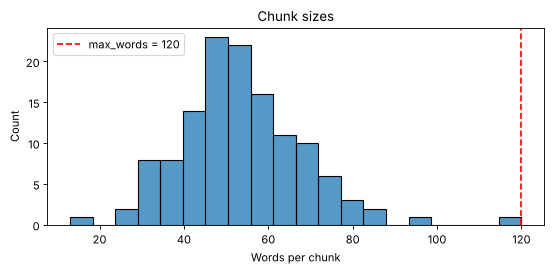

In [6]:
plt.figure(figsize=(7, 3.5))
sns.histplot(chunk_df["words"], bins=20)
plt.axvline(MAX_WORDS, color="red", linestyle="--", label=f"max_words = {MAX_WORDS}")
plt.xlabel("Words per chunk"); plt.title("Chunk sizes"); plt.legend()
plt.tight_layout()

In [7]:
# The one section longer than 120 words is split into overlapping windows. Look at the overlap:
long_parts = chunk_df[chunk_df["heading"] == "Regularisation"]
for _, row in long_parts.iterrows():
    print(row["chunk_id"], "|", row["words"], "words")
    print("   starts:", " ".join(row["text"].split()[:12]), "...")
    print("   ends:  ...", " ".join(row["text"].split()[-12:]))

11_overfitting_regularisation.md#4 | 120 words
   starts: Regularisation adds a penalty for complexity to the loss the model minimises, ...
   ends:  ... and can still overfit. With a very strong penalty all weights are
11_overfitting_regularisation.md#5 | 87 words
   starts: With almost no penalty the model behaves as if it were not ...
   ends:  ... and a feature measured in large units would otherwise be punished unfairly.


**What to notice:** the second "Regularisation" chunk starts with the last 25 words of the first one. That repeated
text is the overlap. Very short chunks also appear (for example a one-sentence "Quick tip" section and the
`### Dropout and early stopping` sub-section is its own chunk because it has its own heading).

## 3. Turning text into vectors

All three methods first split text into tokens with the same function, `se.tokenize`: lowercase, drop common
"stop words" (*the, is, how...*) and strip simple word endings so that *memorising*, *memorises* and *memorised*
become the same token. **The same tokenizer is used for the notes and for every query.**

In [8]:
for text in ["How do I stop my model memorising the training data?",
             "A model overfits when it learns the training examples too closely"]:
    print(text, "\n  ->", se.tokenize(text))

How do I stop my model memorising the training data? 
  -> ['stop', 'model', 'memor', 'train', 'data']
A model overfits when it learns the training examples too closely 
  -> ['model', 'overfit', 'learn', 'train', 'exampl', 'closely']


In [9]:
chunk_texts = [se.text_for_embedding(c) for c in chunks]

keyword = se.KeywordEmbedder().fit(chunk_texts)
tfidf = se.TfidfEmbedder().fit(chunk_texts)
lsa = se.LsaEmbedder(n_components=100, random_state=RANDOM_STATE).fit(chunk_texts)   # size tuned in section 5

for name, emb in [("keyword", keyword), ("tfidf", tfidf), ("lsa", lsa)]:
    vectors = emb.encode(chunk_texts)
    nonzero = (np.abs(vectors) > 1e-9).mean()
    print(f"{name:8s} vectors: {vectors.shape}   share of non-zero numbers: {nonzero:.1%}")

keyword  vectors: (128, 1220)   share of non-zero numbers: 2.2%
tfidf    vectors: (128, 1220)   share of non-zero numbers: 2.2%
lsa      vectors: (128, 100)   share of non-zero numbers: 100.0%


**Reading the shapes:** keyword and TF-IDF vectors have one column per vocabulary word, and almost all numbers are zero
(**sparse**). LSA squeezes them into far fewer columns where almost every number is non-zero (**dense**) — like real
embeddings. Every vector is normalised to length 1, so the **dot product of two vectors is their cosine similarity**.

### Cosine similarity in one example

In [10]:
q = "How do I stop my model memorising the training data?"
target = "11_overfitting_regularisation.md"
for name, emb in [("keyword", keyword), ("tfidf", tfidf), ("lsa", lsa)]:
    store = se.VectorStore(emb.encode(chunk_texts), chunks)
    sims = store.embeddings @ emb.encode([q])[0]
    best = int(np.argmax(sims))
    target_best = max(s for s, c in zip(sims, chunks) if c["doc_id"] == target)
    print(f"{name:8s} best chunk: {chunks[best]['doc_id']:38s} cos={sims[best]:.3f} | "
          f"best overfitting chunk cos={target_best:.3f}")

keyword  best chunk: 13_keras_tensorflow.md                 cos=0.373 | best overfitting chunk cos=0.302
tfidf    best chunk: 13_keras_tensorflow.md                 cos=0.262 | best overfitting chunk cos=0.220
lsa      best chunk: 13_keras_tensorflow.md                 cos=0.591 | best overfitting chunk cos=0.482


**What to notice:** for all three methods the best single chunk is *"Building Models with Keras — Reading the training
history"*. That is not a mistake: this chunk literally says the network "has begun to memorise the training set".
LSA gives larger cosine scores overall (its dense vectors are closer together), so **scores from different methods
cannot be compared with each other** — only the *ranking* within one method matters.

## 4. A tiny vector store and top-k search

`se.VectorStore` is just a NumPy matrix (one row per chunk) plus the list of chunk metadata. Searching means:
embed the query → multiply the matrix by the query vector (cosine scores for **all** chunks at once) → sort → take the top k.
An optional `topic` filter sets the scores of chunks from other topics to minus infinity. This brute-force search is
instant for a few hundred chunks; with millions you would use an approximate nearest-neighbour index (FAISS, HNSW).

In [11]:
lsa_store = se.VectorStore(lsa.encode(chunk_texts), chunks)

def show(query, embedder, store, top_k=3, topic=None, one_per_note=False):
    search = se.search_best_chunk_per_document if one_per_note else se.search_documents
    rows = [{"score": round(s, 3), "title": c["title"], "heading": c["heading"]}
            for c, s in search(embedder, store, query, top_k=top_k, topic=topic)]
    return pd.DataFrame(rows)

show("how do I stop my model memorising the training data", lsa, lsa_store)

,score,title,heading
0,0.591,Building Models with Keras,Reading the training history
1,0.562,Building Models with Keras,Callbacks
2,0.482,Overfitting and Regularisation,What overfitting looks like


**Problem:** two of the top 3 places can go to sections of the **same** note. For a student it is more useful to see
3 *different* notes, each with its best section. `se.search_best_chunk_per_document` keeps only the best chunk of each
note (the API uses this version):

In [12]:
show("how do I stop my model memorising the training data", lsa, lsa_store, one_per_note=True)

,score,title,heading
0,0.591,Building Models with Keras,Reading the training history
1,0.482,Overfitting and Regularisation,What overfitting looks like
2,0.383,Large Language Models,Hallucinations and other limitations


In [13]:
# The same query, but only searching inside the "Deep Learning" topic (a metadata filter)
show("how do I stop my model memorising the training data", lsa, lsa_store, topic="Deep Learning", one_per_note=True)

,score,title,heading
0,0.591,Building Models with Keras,Reading the training history
1,0.255,Neural Networks,Batches and epochs


## 5. Evaluating retrieval honestly

We score each method on the labelled queries at **document level** (a note counts as found if any of its chunks is
found):

- **hit@1** — share of queries where the expected note is the very first result,
- **hit@3** — share of queries where it is in the top 3 (a student will look at about three results),
- **MRR** (mean reciprocal rank) — average of 1 / rank: rank 1 → 1.0, rank 2 → 0.5, rank 3 → 0.33. Higher is better.

**Avoid fooling ourselves.** LSA has a setting, the number of dimensions (`n_components`). If we tried many values and
reported the best score on the same queries, the score would be too optimistic. So we split the 30 answerable queries:
odd `query_id` = **tuning** queries (choose `n_components`), even `query_id` = **held-out** queries (final comparison).

In [14]:
answerable = queries[queries["expected_doc"] != "none"].reset_index(drop=True)
tune_q = answerable[answerable["query_id"] % 2 == 1]
test_q = answerable[answerable["query_id"] % 2 == 0]
print("Tuning queries:", len(tune_q), "  Held-out queries:", len(test_q))

def rank_of_expected(embedder, store, query, expected):
    ranked = [doc for doc, _ in se.rank_documents(embedder, store, query, top_k=len(docs))]
    return ranked.index(expected) + 1

def evaluate(embedder, store, qdf):
    ranks = np.array([rank_of_expected(embedder, store, r.query, r.expected_doc) for r in qdf.itertuples()])
    return {"hit@1": (ranks == 1).mean(), "hit@3": (ranks <= 3).mean(), "MRR": (1 / ranks).mean()}, ranks

Tuning queries: 15   Held-out queries: 15


In [15]:
tuning_rows = []
for k in [10, 20, 30, 40, 50, 60, 80, 100]:
    emb = se.LsaEmbedder(n_components=k, random_state=RANDOM_STATE).fit(chunk_texts)
    scores, _ = evaluate(emb, se.VectorStore(emb.encode(chunk_texts), chunks), tune_q)
    tuning_rows.append({"n_components": k, **scores})
tuning = pd.DataFrame(tuning_rows).set_index("n_components").round(3)
tuning

,hit@1,hit@3,MRR
n_components,,,
10,0.600,0.800,0.736
20,0.600,0.933,0.775
30,0.733,0.933,0.836
40,0.667,0.933,0.817
50,0.667,1.000,0.811
60,0.533,1.000,0.733
80,0.533,1.000,0.744
100,0.533,1.000,0.756


Chosen n_components (best MRR on TUNING queries): 30


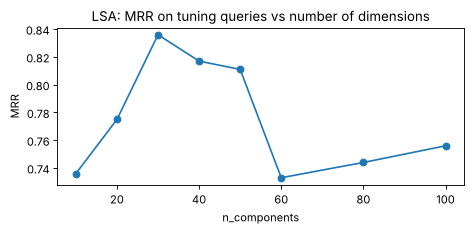

In [16]:
BEST_K = int(tuning["MRR"].idxmax())
print("Chosen n_components (best MRR on TUNING queries):", BEST_K)

ax = tuning["MRR"].plot(marker="o", figsize=(6, 3), title="LSA: MRR on tuning queries vs number of dimensions")
ax.set_ylabel("MRR"); plt.tight_layout()

The curve is bumpy: with only 15 tuning queries, one query moving up or down one place changes MRR noticeably.
Treat the chosen value as "a reasonable setting", not as a precise optimum.

Now the fair comparison of the three methods on the **held-out** queries (never used for any choice) and, for
information, on all 30 answerable queries.

In [17]:
lsa = se.LsaEmbedder(n_components=BEST_K, random_state=RANDOM_STATE).fit(chunk_texts)
methods = {"keyword": keyword, "tfidf": tfidf, "lsa": lsa}
stores = {name: se.VectorStore(emb.encode(chunk_texts), chunks) for name, emb in methods.items()}

rows, all_ranks = [], {}
for name, emb in methods.items():
    held, _ = evaluate(emb, stores[name], test_q)
    full, ranks = evaluate(emb, stores[name], answerable)
    all_ranks[name] = ranks
    rows.append({"method": name,
                 "held-out hit@1": held["hit@1"], "held-out hit@3": held["hit@3"], "held-out MRR": held["MRR"],
                 "all-30 hit@1": full["hit@1"], "all-30 hit@3": full["hit@3"], "all-30 MRR": full["MRR"]})
comparison = pd.DataFrame(rows).set_index("method").round(3)
comparison

,held-out hit@1,held-out hit@3,held-out MRR,all-30 hit@1,all-30 hit@3,all-30 MRR
method,,,,,,
keyword,0.733,1.000,0.833,0.567,0.900,0.716
tfidf,0.667,0.933,0.806,0.600,0.933,0.772
lsa,0.733,0.933,0.844,0.733,0.933,0.840


In [18]:
# Break the HELD-OUT results down by query type: do the methods differ on the hard "no shared words" queries?
per_type = answerable[["query_id", "query", "expected_doc", "query_type"]].copy()
for name in methods:
    per_type[f"rank_{name}"] = all_ranks[name]
held_out = per_type[per_type["query_id"] % 2 == 0]
by_type = pd.DataFrame({
    name: held_out.groupby("query_type")[f"rank_{name}"].apply(lambda r: (1 / r).mean()) for name in methods
}).round(3)
by_type["queries"] = held_out["query_type"].value_counts()
by_type.index.name = "held-out MRR by type"
by_type

,keyword,tfidf,lsa,queries
held-out MRR by type,,,,
no_overlap,0.643,0.655,0.738,7
paraphrase,1.000,0.938,0.938,8


**Reading the results honestly:**
- On the 15 **held-out** queries the three methods are close: LSA and keyword both reach hit@1 = 0.733, and LSA's MRR
  (0.844) is only 0.011 above keyword's (0.833) — that is less than one query moving one place. Keyword search even
  has a perfect held-out hit@3. With so few queries we **cannot** claim LSA is better overall.
- On all 30 queries LSA looks clearly better (MRR 0.840 vs 0.716), but half of those queries were used to choose
  `n_components`, so that number is optimistic.
- The type breakdown is where the difference shows: check the `no_overlap` row in the table above — the queries this
  project is about (different words, same meaning).

## 6. Where does LSA beat keyword search — and where does it fail?

In [19]:
better = per_type[per_type["rank_lsa"] < per_type["rank_keyword"]]
print(f"LSA ranks the right note higher than keyword search for {len(better)} of {len(per_type)} queries:")
better[["query", "query_type", "rank_keyword", "rank_tfidf", "rank_lsa"]]

LSA ranks the right note higher than keyword search for 9 of 30 queries:


,query,query_type,rank_keyword,rank_tfidf,rank_lsa
0,how do I stop my model memorising the training data,paraphrase,3,2,2
1,my model is great on the data it learned from but terrible on new examples,no_overlap,3,2,1
6,difference between precision and recall,paraphrase,2,1,1
8,split shoppers into groups that behave alike without labels,no_overlap,2,3,1
12,which chart shows the spread of one number column,paraphrase,2,1,1
16,is the gap between version A and version B of my website real or luck,no_overlap,3,4,1
24,why does the chatbot confidently invent facts that are not true,no_overlap,8,2,1
27,let a chatbot answer questions about my own private documents,no_overlap,3,1,1
28,put my trained model online so a web page can use it,no_overlap,6,1,1


In [20]:
worse = per_type[per_type["rank_lsa"] > per_type["rank_keyword"]]
print(f"LSA ranks the right note LOWER than keyword search for {len(worse)} queries:")
worse[["query", "query_type", "rank_keyword", "rank_tfidf", "rank_lsa"]]

LSA ranks the right note LOWER than keyword search for 4 queries:


,query,query_type,rank_keyword,rank_tfidf,rank_lsa
3,fill in the blanks in a spreadsheet column before training,no_overlap,3,4,6
23,how does a model know which earlier words matter for the current word,no_overlap,1,2,2
25,give the model a few worked examples inside the request,paraphrase,1,2,2
26,find text with similar meaning even when different words are used,paraphrase,1,2,2


In [21]:
# Failures of the chosen method: the expected note is not the first result. What came first instead?
fails = per_type[per_type["rank_lsa"] > 1].copy()
fails["lsa_top_result"] = [se.rank_documents(lsa, stores["lsa"], q, top_k=1)[0][0] for q in fails["query"]]
fails[["query", "expected_doc", "rank_lsa", "lsa_top_result"]]

,query,expected_doc,rank_lsa,lsa_top_result
0,how do I stop my model memorising the training data,11_overfitting_regularisation.md,2,13_keras_tensorflow.md
3,fill in the blanks in a spreadsheet column before training,05_data_preprocessing.md,6,02_pandas_dataframes.md
4,turn city names into numbers for a model,05_data_preprocessing.md,5,14_nlp_fundamentals.md
10,find the best settings for a model before training,10_cross_validation.md,3,13_keras_tensorflow.md
11,draw a picture to compare categories and spot strange values,03_data_visualization.md,2,05_data_preprocessing.md
23,how does a model know which earlier words matter for the current word,15_transformers_attention.md,2,14_nlp_fundamentals.md
25,give the model a few worked examples inside the request,17_prompt_engineering.md,2,20_deployment_basics.md
26,find text with similar meaning even when different words are used,18_embeddings_vector_search.md,2,14_nlp_fundamentals.md


In [22]:
# Which tokens does each query share with its expected note (after tokenizing)? 2 failures, then 2 LSA successes
examples = fails["query_id"].head(2).tolist() + better[~better["query_id"].isin(fails["query_id"])]["query_id"].head(2).tolist()
for qid in examples:
    row = answerable[answerable["query_id"] == qid].iloc[0]
    note_words = set(se.tokenize(next(d["text"] for d in docs if d["doc_id"] == row["expected_doc"])))
    shared = sorted(set(se.tokenize(row["query"])) & note_words)
    print(f"[{qid}] {row['query']}\n     shared tokens with {row['expected_doc']}: {shared}")

[1] how do I stop my model memorising the training data
     shared tokens with 11_overfitting_regularisation.md: ['data', 'memor', 'model', 'stop', 'train']
[4] fill in the blanks in a spreadsheet column before training
     shared tokens with 05_data_preprocessing.md: ['column', 'train']
[2] my model is great on the data it learned from but terrible on new examples
     shared tokens with 11_overfitting_regularisation.md: ['data', 'exampl', 'learn', 'model', 'new']
[7] difference between precision and recall
     shared tokens with 08_classification_metrics.md: ['precision', 'recall']


**What the tables show:**
- LSA ranks the right note higher than keyword search for **9 of 30** queries, and 6 of those 9 are `no_overlap`
  queries — for example *"why does the chatbot confidently invent facts that are not true"* moves from rank 8 to rank 1
  (Large Language Models), and *"put my trained model online so a web page can use it"* from rank 6 to rank 1.
- LSA is worse for **4** queries. The clearest failure is *"fill in the blanks in a spreadsheet column before
  training"* (rank 6): *blanks* and *spreadsheet* never appear in the notes in this sense, so only *column* and *train*
  are left, and those point to the pandas note.
- **8 queries are not ranked first by LSA**; in 6 of them the right note is still second, behind a closely related
  note (for example the Keras note, which also talks about memorising the training set). A student looking at the top 3
  still finds the answer for all but 2 queries (ranks 5 and 6).
- LSA does **not** understand language. It only learns which words appear in the same notes. A query word that never
  appears in any note is ignored completely.

## 7. "No good match": what about questions the notes do not cover?

Cosine search **always** returns something, even for *"cheapest flights from mumbai to goa"*. We need a signal for
"the notes do not contain this". The raw LSA score alone is not reliable. In that query only *mumbai* is a known word
(it appears in the preprocessing note as an example city), yet the best cosine score is very high (0.94, printed
below), because the query vector is built from that single word.

We therefore combine two things:

`confidence = best cosine score × coverage`, where **coverage** = share of the query's tokens that exist in the notes'
vocabulary. Off-topic questions are mostly made of unknown words, so their coverage is low.

In [23]:
conf_rows = []
for r in queries.itertuples():
    best = se.search_documents(lsa, stores["lsa"], r.query, top_k=1)
    coverage, unknown = se.query_coverage(lsa, r.query)
    confidence, _ = se.match_confidence(lsa, stores["lsa"], r.query)
    conf_rows.append({"query": r.query, "type": r.query_type,
                      "best_cosine": round(best[0][1], 3) if best else 0.0,
                      "coverage": round(coverage, 2), "confidence": round(confidence, 3), "unknown_words": unknown})
conf = pd.DataFrame(conf_rows)
print(conf[conf["query"].str.contains("mumbai")][["query", "best_cosine", "coverage", "confidence"]].to_string())
conf.sort_values("confidence").head(10)

                                  query  best_cosine  coverage  confidence
32  cheapest flights from mumbai to goa         0.94      0.25       0.235


,query,type,best_cosine,coverage,confidence,unknown_words
31,who won the football world cup,off_topic,0.000,0.00,0.000,"[won, football, world, cup]"
30,best recipe for chicken biryani,off_topic,0.710,0.25,0.177,"[recipe, chicken, biryani]"
32,cheapest flights from mumbai to goa,off_topic,0.940,0.25,0.235,"[cheapest, flight, goa]"
34,where do pythons live in the wild,off_topic,0.845,0.33,0.282,"[live, wild]"
33,how do I train my puppy to sit,off_topic,0.649,0.67,0.433,[puppy]
8,split shoppers into groups that behave alike without labels,no_overlap,0.682,0.67,0.454,"[shopper, alike]"
16,is the gap between version A and version B of my website real or luck,no_overlap,0.695,0.67,0.463,"[website, luck]"
1,my model is great on the data it learned from but terrible on new examples,no_overlap,0.658,0.71,0.470,"[great, terrible]"
24,why does the chatbot confidently invent facts that are not true,no_overlap,0.597,0.80,0.478,[chatbot]
11,draw a picture to compare categories and spot strange values,no_overlap,0.676,0.71,0.483,"[spot, strange]"


Highest off-topic confidence: 0.433   Lowest answerable confidence: 0.454


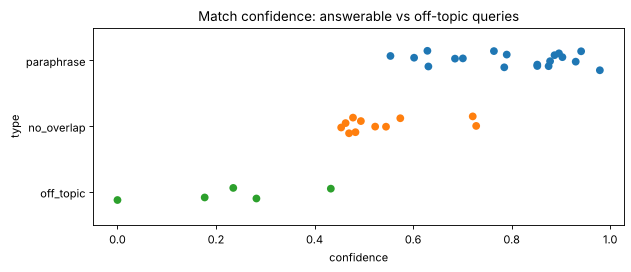

In [24]:
plt.figure(figsize=(8, 3.5))
sns.stripplot(data=conf, x="confidence", y="type", hue="type", size=7, jitter=0.15, legend=False)
plt.title("Match confidence: answerable vs off-topic queries"); plt.tight_layout()

off = conf[conf["type"] == "off_topic"]["confidence"]
on = conf[conf["type"] != "off_topic"]["confidence"]
print(f"Highest off-topic confidence: {off.max():.3f}   Lowest answerable confidence: {on.min():.3f}")

In [25]:
# Choose the threshold: compare a few candidate values
threshold_rows = []
for t in [0.25, 0.30, 0.35, 0.40, 0.45]:
    threshold_rows.append({"threshold": t,
                           "off-topic correctly flagged": f"{(off < t).sum()} / {len(off)}",
                           "answerable wrongly flagged": f"{(on < t).sum()} / {len(on)}"})
pd.DataFrame(threshold_rows)

,threshold,off-topic correctly flagged,answerable wrongly flagged
0,0.25,3 / 5,0 / 30
1,0.30,4 / 5,0 / 30
2,0.35,4 / 5,0 / 30
3,0.40,4 / 5,0 / 30
4,0.45,5 / 5,0 / 30


In [26]:
MIN_CONFIDENCE = 0.30
print(f"Chosen threshold: {MIN_CONFIDENCE}")
print("Off-topic queries NOT flagged at this threshold:")
print(conf[(conf["type"] == "off_topic") & (conf["confidence"] >= MIN_CONFIDENCE)][["query", "confidence"]])

Chosen threshold: 0.3
Off-topic queries NOT flagged at this threshold:
                             query  confidence
33  how do I train my puppy to sit       0.433


**Choosing the threshold:** the gap between the two groups is tiny: the highest off-topic confidence is 0.433 (*"how do
I train my puppy to sit"*: *train* and *sit* both appear in the notes, only *puppy* is unknown) and the lowest answerable one is
0.454. A threshold of 0.45 would separate this test set perfectly, but it sits right at the edge of real questions, so
new real questions would often be flagged by mistake. Hiding a real answer is worse for a student than showing a weak
result with a warning, so we choose **0.30**: no answerable query is flagged and 4 of the 5 off-topic queries are. The API does
not hide results below the threshold; it returns them together with `good_match: false` and the frontend shows a
"no good match" message above them. With only 5 off-topic test queries this threshold is a rough rule, not a
measured guarantee.

## 8. Choosing the method — with evidence

Rule decided before looking: pick the method with the best **held-out MRR**, ties broken by hit@3.

In [27]:
ranking = comparison.sort_values(["held-out MRR", "held-out hit@3"], ascending=False)
CHOSEN = ranking.index[0]
print("Chosen method:", CHOSEN)
print(ranking[["held-out hit@1", "held-out hit@3", "held-out MRR", "all-30 MRR"]])

Chosen method: lsa
         held-out hit@1  held-out hit@3  held-out MRR  all-30 MRR
method                                                           
lsa               0.733           0.933         0.844       0.840
keyword           0.733           1.000         0.833       0.716
tfidf             0.667           0.933         0.806       0.772


**Decision: LSA**, with a clear statement of how strong the evidence is. It wins the rule above only by a hair over the
keyword baseline (held-out MRR 0.844 vs 0.833). We still prefer it because its advantage is concentrated on the
`no_overlap` queries — exactly the "search by meaning" problem we were asked to solve — while on ordinary paraphrases
it is about as good as keywords. If the held-out numbers had favoured keyword search, the honest choice would have been
keyword search plus a better embedding model later.

## 9. See the embedding space in 2D

Our LSA vectors have many dimensions. PCA projects them onto the 2 directions with the most variation so we can look
at them. Each dot is a chunk, coloured by topic; the black star is a query. Some information is lost in the
projection, so points that overlap here may be further apart in the full space.

Variance kept by the 2D picture: 11.6%


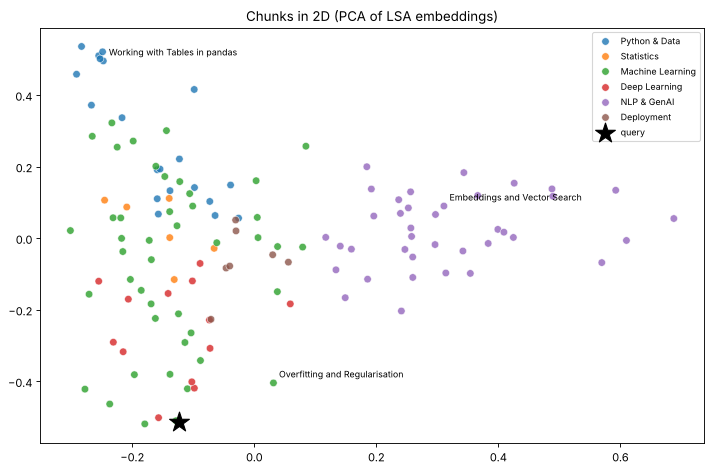

In [28]:
lsa_vectors = stores["lsa"].embeddings
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(lsa_vectors)
points = pca.transform(lsa_vectors)
query_text = "how do I stop my model memorising the training data"
qpoint = pca.transform(lsa.encode([query_text]))[0]

plt.figure(figsize=(9, 6))
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=chunk_df["topic"], s=45, alpha=0.8)
plt.scatter(*qpoint, marker="*", s=350, color="black", label="query")
for doc_id in ["11_overfitting_regularisation.md", "18_embeddings_vector_search.md", "02_pandas_dataframes.md"]:
    idx = chunk_df.index[chunk_df["doc_id"] == doc_id][0]
    plt.annotate(chunks[idx]["title"], points[idx], fontsize=8, xytext=(5, 5), textcoords="offset points")
plt.title("Chunks in 2D (PCA of LSA embeddings)"); plt.legend(fontsize=8, loc="best")
plt.tight_layout()
print(f"Variance kept by the 2D picture: {pca.explained_variance_ratio_.sum():.1%}")

In [29]:
# Which words define the first LSA dimensions? (the "topics" LSA discovered)
terms = np.array(lsa.vectorizer.get_feature_names_out())
for i in range(4):
    top = terms[np.argsort(-lsa.svd.components_[i])[:8]]
    print(f"Dimension {i}: {', '.join(top)}")

Dimension 0: model, train, data, test, validation, mean, text, learn
Dimension 1: prompt, answer, chunk, retrieval, document, augment, rag, embedd
Dimension 2: column, df, row, price, panda, tabl, work, valu
Dimension 3: word, vector, embedd, weight, transformer, mean, attention, regression


## 10. Save the index for the API

The API must embed queries **exactly** like the chunks were embedded, so we save the fitted pieces:

| File | Content |
|---|---|
| `models/vectorizer.joblib` | fitted TF-IDF vectorizer (vocabulary + IDF weights) |
| `models/svd.joblib` | fitted TruncatedSVD (the LSA projection) |
| `models/embeddings.npy` | one normalised vector per chunk (the "vector database") |
| `models/chunks.json` | metadata + text for every chunk, in the same order as the rows of `embeddings.npy` |
| `models/index_info.json` | method, settings, threshold, metrics, topics and documents — used by the API |

The vectorizer uses `se.tokenize`, so the API must import the same `search_engine.py` module (it does).

In [30]:
os.makedirs("models", exist_ok=True)
final = methods[CHOSEN]
joblib.dump(final.vectorizer, "models/vectorizer.joblib")
if CHOSEN == "lsa":
    joblib.dump(final.svd, "models/svd.joblib")
stores[CHOSEN].save("models/embeddings.npy", "models/chunks.json")

index_info = {
    "embedding_method": CHOSEN,
    "n_components": BEST_K if CHOSEN == "lsa" else None,
    "chunking": {"max_words": MAX_WORDS, "overlap_words": OVERLAP, "split_on": "## and ### headings, then paragraphs"},
    "n_chunks": len(chunks),
    "n_documents": len(docs),
    "embedding_dim": int(stores[CHOSEN].embeddings.shape[1]),
    "min_confidence": MIN_CONFIDENCE,
    "max_query_chars": 300,
    "topics": sorted(doc_table["topic"].unique().tolist()),
    "documents": doc_table[["doc_id", "title", "topic"]].to_dict(orient="records"),
    "metrics_held_out": {k.replace("held-out ", ""): float(v) for k, v in comparison.loc[CHOSEN].items()
                         if k.startswith("held-out")},
    "metrics_all_methods": comparison.reset_index().to_dict(orient="records"),
}
with open("models/index_info.json", "w") as f:
    json.dump(index_info, f, indent=2)
print(json.dumps(index_info["metrics_held_out"], indent=2))
print(sorted(os.listdir("models")))

{
  "hit@1": 0.733,
  "hit@3": 0.933,
  "MRR": 0.844
}
['chunks.json', 'embeddings.npy', 'index_info.json', 'svd.joblib', 'vectorizer.joblib']


In [31]:
# Reload everything from disk exactly as the API does, and check that search gives identical results
reloaded = se.LsaEmbedder(vectorizer=joblib.load("models/vectorizer.joblib"), svd=joblib.load("models/svd.joblib"))
reloaded_store = se.VectorStore.load("models/embeddings.npy", "models/chunks.json")
test_query = "turn city names into numbers for a model"
before = se.search_documents(lsa, stores["lsa"], test_query, top_k=3)
after = se.search_documents(reloaded, reloaded_store, test_query, top_k=3)
assert [c["chunk_id"] for c, _ in before] == [c["chunk_id"] for c, _ in after]
assert np.allclose([s for _, s in before], [s for _, s in after], atol=1e-5)
print("Reloaded index gives identical results:")
for c, s in after:
    print(f"  {s:.3f}  {c['title']} — {c['heading']}")

Reloaded index gives identical results:
  0.602  NLP Fundamentals — What NLP is
  0.534  Python Basics for Data Science — Variables and data types
  0.523  Large Language Models — Hallucinations and other limitations


## 11. Alternative: a real neural embedding model (not run here)

The cell below shows how to replace LSA with a pre-trained **sentence-transformers** model. Such models were trained on
millions of sentence pairs, so they know that *memorising* is related to *overfitting* even if no course note links the
two words. It is **not executed** in this build because the library is not installed and the model (about 90 MB) must
be downloaded from the internet. We therefore make **no claim** about its scores; run the cell yourself and compare the
numbers with the table in section 5. The API can use it with `EMBEDDING_BACKEND=sentence-transformers` (see README).

In [ ]:
# NO-RUN  (needs: pip install sentence-transformers  + internet access the first time to download the model)
st_embedder = se.SentenceTransformerEmbedder("all-MiniLM-L6-v2")      # 384-dimensional neural embeddings
st_store = se.VectorStore(st_embedder.encode(chunk_texts), chunks)
st_scores, st_ranks = evaluate(st_embedder, st_store, test_q)
print("sentence-transformers on held-out queries:", st_scores)
# Note: query_coverage() returns 1.0 for neural models (no vocabulary), so the 'no good match' threshold
# must be re-chosen from the cosine scores of this model (repeat section 7 with it).

## 12. Limitations and next steps

- **LSA is not a true neural embedding.** It only learns which words appear together *in these 20 notes*. A query
  word that never appears in the notes (e.g. *spreadsheet*, *chatbot*) is ignored completely. Synonyms are only
  linked when the notes themselves use them near each other.
- **Small corpus, small test set.** 20 notes, ~130 chunks and 30 labelled queries: one query changes hit@1 by more than
  3 percentage points. The ranking of methods could change with more queries.
- **The test queries were written by the same author as the notes**, which is easier than real student questions with
  typos and slang.
- **The "no good match" threshold** was chosen from only 5 off-topic queries.
- **Adding a note means rebuilding the index** (re-fit the vectorizer and SVD, re-embed every chunk), because the
  vocabulary and dimensions depend on the whole collection. With a pre-trained neural model, new chunks can simply be
  embedded and appended.
- **When you need more:** a downloaded model such as sentence-transformers (free, runs on a laptop CPU) or a paid
  embedding API (no local model, but costs per token and sends your text to a third party) gives far better synonym
  handling. For millions of chunks, use a vector database (FAISS, Chroma, Qdrant, pgvector) instead of a NumPy matrix.
- **Ideas to improve:** hybrid search (combine keyword and LSA scores), a spelling corrector for queries, re-ranking the
  top 10 with a stronger model, and logging real student queries to grow the evaluation set.

**Next step:** start the Flask API in `backend/` (see the project README). It loads the files saved in section 10.